**Non-Interest-Bearing Deposits (Checking)**

Economic Variables / Relevance
1. Real GDP - cumulative trend, non-stationary; use growth instead for quarterly shifts
2. Real GDP growth - directly boosts payroll deposits from higher economic activity **(*Selected*)**
3. Nominal GDP - same issue as Real GDP level; growth matters, not absolute size
4. Nominal GDP growth - captures inflation-driven higher dollar values in transactions **(*Selected*)**
5. Real disposable income - trends up forever; growth captures the action for deposits
6. Real disposable income growth - reflects inflation-adjusted increases in household income available for spending, boosting cash flow into checking accounts **(*Selected*)**
7. Nominal disposable income - non-stationary level; stick to growth for income flow effects
8. Nominal disposable income growth - includes inflation effects already captured by CPI and nominal GDP growth; redundant for checking flow analysis 
9. Unemployment rate - job losses reduce incoming payroll, shrinking average balances **(*Selected*)**
10. Consumer Price Index (Level) - raw index trends up; inflation rate is what erodes value
11. CPI inflation rate - erodes real value, but still pads nominal checking totals short-term **(*Selected*)**
12. 3-month Treasury rate - short-term alternative lures funds out when it spikes above checking's zero yield **(*Selected*)**
13. 5-year Treasury yield - too medium-term; people don't shift daily cash for 5-year locks
14. 10-year Treasury yield - long-term investment yield, irrelevant to liquid checking flow
15. BBB corporate yield - for investors chasing yield; an investment choice, not a liquidity play. Plus, it's highly collinear with 3-month Treasury and Prime (same rate environment)
16. Mortgage rate - ties to home buying, not payroll or cash flow into accounts
17. Prime rate - affects business borrowing, indirectly timing payroll deposits for small firms **(*Selected*)**
18. Dow Jones Total Stock Market Index (Level) - stock gains might inspire spending, but checking isn't an investment pool-it's spending cash 
19. House Price Index (Level) - rising homes pull equity out via loans, not from checking
20. Commercial Real Estate Price Index (Level) - business property market; no direct link to consumer checking
21. Market Volatility Index (Level) - high fear might boost cash hoarding, but it's weak, lagged, and buried in GDP/unemployment signals

In [2]:
import pandas as pd
import numpy as np

In [3]:
#Load merged historic data
merged_historic = pd.read_csv('merged_historic.csv', index_col='Date', parse_dates=True)

In [4]:
merged_historic.head()

,Non_Maturity_IB,Non_Interest_Bearing,Time_Deposits,Real GDP,Real GDP growth,Nominal GDP,Nominal GDP growth,Real disposable income,Real disposable income growth,Nominal disposable income,...,Dow Jones Total Stock Market Index (Level),House Price Index (Level),Commercial Real Estate Price Index (Level),Market Volatility Index (Level),Consumer Price Index (Level),Non_IB_Growth,Non_Mat_IB_Growth,Time_Growth,GFC_Dummy,COVID_Dummy
Date,,,,,,,,,,,,,,,,,,,,,
1991-06-30,1098276.374,454615.450,1706710.057,10029.510,3.2,6126.862,6.2,7271.400000,3.0,4474.433333,...,3545.5,75.5,104.6,20.1,135.567,NaN,NaN,NaN,0,0
1991-09-30,1125986.253,475201.761,1679959.999,10080.195,2.0,6205.937,5.3,7299.333333,1.5,4522.066667,...,3744.0,75.2,101.0,21.2,136.600,4.528291,2.523033,-1.567346,0,0
1991-12-31,1184866.053,491843.215,1613051.671,10115.329,1.4,6264.540,3.8,7356.666667,3.2,4590.566667,...,4041.1,75.0,97.6,21.9,137.733,3.501977,5.229176,-3.982733,0,0
1992-03-31,1246734.189,483989.015,1534806.930,10236.435,4.9,6363.102,6.4,7498.600000,7.9,4708.400000,...,3961.6,75.2,95.4,19.8,138.667,-1.596891,5.221530,-4.850728,0,0
1992-06-30,1265699.776,496919.561,1467776.199,10347.429,4.4,6470.763,6.9,7568.933333,3.8,4784.100000,...,3930.3,75.0,93.2,20.2,139.733,2.671661,1.521221,-4.367372,0,0


In [5]:
#Load scenarios data
scenarios = pd.read_csv('scenarios.csv', index_col=['Scenario Name', 'Date'], parse_dates=['Date'], date_format='%Y-%m-%d')

In [6]:
scenarios.head()

Real GDP  Real GDP growth   Nominal GDP  \
Scenario Name        Date                                                      
Supervisory Baseline 2024-03-31  22735.953138              1.0  28180.653984   
                     2024-06-30  22775.741055              0.7  28384.963725   
                     2024-09-30  22826.986473              0.9  28604.947194   
                     2024-12-31  22912.587672              1.5  28862.391719   
                     2025-03-31  23015.694317              1.8  29158.231234   

                                 Nominal GDP growth  Real disposable income  \
Scenario Name        Date                                                     
Supervisory Baseline 2024-03-31                 3.2            16961.584792   
                     2024-06-30                 2.9            17037.911923   
                     2024-09-30                 3.1            17114.582527   
                     2024-12-31                 3.6            17200.155440   
                     2025-03-31                 4.1            17303.356372   

                                 Real disposable income growth  \
Scenario Name        Date                                        
Supervisory Baseline 2024-03-31                            2.5   
                     2024-06-30                            1.8   
                     2024-09-30                            1.8   
                     2024-12-31                            2.0   
                     2025-03-31                            2.4   

                                 Nominal disposable income  \
Scenario Name        Date                                    
Supervisory Baseline 2024-03-31               20690.266217   
                     2024-06-30               20897.168879   
                     2024-09-30               21106.140568   
                     2024-12-31               21322.478508   
                     2025-03-31               21562.356392   

                                 Nominal disposable income growth  \
Scenario Name        Date                                           
Supervisory Baseline 2024-03-31                               4.6   
                     2024-06-30                               4.0   
                     2024-09-30                               4.0   
                     2024-12-31                               4.1   
                     2025-03-31                               4.5   

                                 Unemployment rate  \
Scenario Name        Date                            
Supervisory Baseline 2024-03-31                3.9   
                     2024-06-30                4.1   
                     2024-09-30                4.2   
                     2024-12-31                4.3   
                     2025-03-31                4.3   

                                 Consumer Price Index (Level)  ...  \
Scenario Name        Date                                      ...   
Supervisory Baseline 2024-03-31                    309.931186  ...   
                     2024-06-30                    311.698122  ...   
                     2024-09-30                    313.551711  ...   
                     2024-12-31                    315.339289  ...   
                     2025-03-31                    317.059527  ...   

                                 3-month Treasury rate  5-year Treasury yield  \
Scenario Name        Date                                                       
Supervisory Baseline 2024-03-31                    5.3                    4.2   
                     2024-06-30                    5.0                    4.0   
                     2024-09-30                    4.6                    3.9   
                     2024-12-31                    4.2                    3.8   
                     2025-03-31                    3.9                    3.6   

                                 10-year Treasury yield  BBB corporate yield  \
Scenario Name        D

In [7]:
# Non-Interest-Bearing deposits (endogenous variable)
y = merged_historic['Non_Interest_Bearing']

In [8]:
print("Non-Interest-Bearing deposits Statistics")
y.describe() 

Non-Interest-Bearing deposits Statistics


count    1.310000e+02
mean     1.888082e+06
std      1.405839e+06
min      4.546155e+05
25%      7.190829e+05
50%      1.207845e+06
75%      2.983428e+06
max      5.517936e+06
Name: Non_Interest_Bearing, dtype: float64

In [9]:
# Selected exogenous variables
exogs = ['Real GDP growth', 'Nominal GDP growth', 'Real disposable income growth', 'Unemployment rate', 'CPI inflation rate', '3-month Treasury rate', 'Prime rate', 'GFC_Dummy', 'COVID_Dummy']
X = merged_historic[exogs]


In [10]:
print("Statistics of Economic Variables relevant to Non-Interest-Bearing deposits")
X.describe() 


Statistics of Economic Variables relevant to Non-Interest-Bearing deposits


,Real GDP growth,Nominal GDP growth,Real disposable income growth,Unemployment rate,CPI inflation rate,3-month Treasury rate,Prime rate,GFC_Dummy,COVID_Dummy
count,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000
mean,2.633588,4.906107,2.884733,5.756489,2.580153,2.432061,5.647328,0.061069,0.061069
std,4.561943,5.151441,7.658806,1.773441,2.208251,2.073172,2.122420,0.240376,0.240376
min,-28.000000,-29.200000,-27.600000,3.500000,-8.900000,0.000000,3.300000,0.000000,0.000000
25%,1.550000,3.600000,1.350000,4.400000,1.750000,0.200000,3.300000,0.000000,0.000000
50%,2.600000,5.000000,2.800000,5.400000,2.700000,2.000000,5.200000,0.000000,0.000000
75%,4.050000,6.500000,4.300000,6.750000,3.500000,4.650000,8.000000,0.000000,0.000000
max,34.800000,39.700000,56.000000,13.000000,9.700000,6.000000,9.500000,1.000000,1.000000


In [11]:
from statsmodels.tsa.stattools import adfuller

In [12]:
# First difference
y_diff = y.diff().dropna()

In [13]:
# ADF test on differenced series
adf_result_diff = adfuller(y_diff)
print(f'ADF Statistic (diff=1): {adf_result_diff[0]:.4f}')
print(f'p-value (diff=1): {adf_result_diff[1]:.4f}')
print(f'Critical Values (diff=1): {adf_result_diff[4]}')
if adf_result_diff[1] > 0.05:
    print('Still non-stationary - may need higher differencing')
else:
    print('Stationary after diff=1 (d=1 likely needed)')

ADF Statistic (diff=1): -2.5939
p-value (diff=1): 0.0943
Critical Values (diff=1): {'1%': -3.4880216384691867, '5%': -2.8867966864160075, '10%': -2.5802408234244947}
Still non-stationary - may need higher differencing


Can not reject null hypothesis, from the above stats.

Non-Interest-Bearing deposits might have a stronger trend or structural break (e.g., post-2008 growth spurt) that one difference didn’t fully flatten. This could reflect persistent income growth or policy effects (like stimulus) not yet accounted for.

In [14]:
y_diff2 = y.diff().diff().dropna()

In [15]:
# ADF test on double-differenced series
adf_result_diff2 = adfuller(y_diff2)
print(f'ADF Statistic (diff=2): {adf_result_diff2[0]:.4f}')
print(f'p-value (diff=2): {adf_result_diff2[1]:.10f}')
print(f'Critical Values (diff=2): {adf_result_diff2[4]}')
if adf_result_diff2[1] > 0.05:
    print('Still non-stationary - may need higher differencing')
else:
    print('Stationary after diff=2 (d=2 likely needed)')

ADF Statistic (diff=2): -6.6523
p-value (diff=2): 0.0000000051
Critical Values (diff=2): {'1%': -3.4880216384691867, '5%': -2.8867966864160075, '10%': -2.5802408234244947}
Stationary after diff=2 (d=2 likely needed)


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
import os
os.makedirs('graphs', exist_ok=True)

In [18]:
# Set style for plots
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

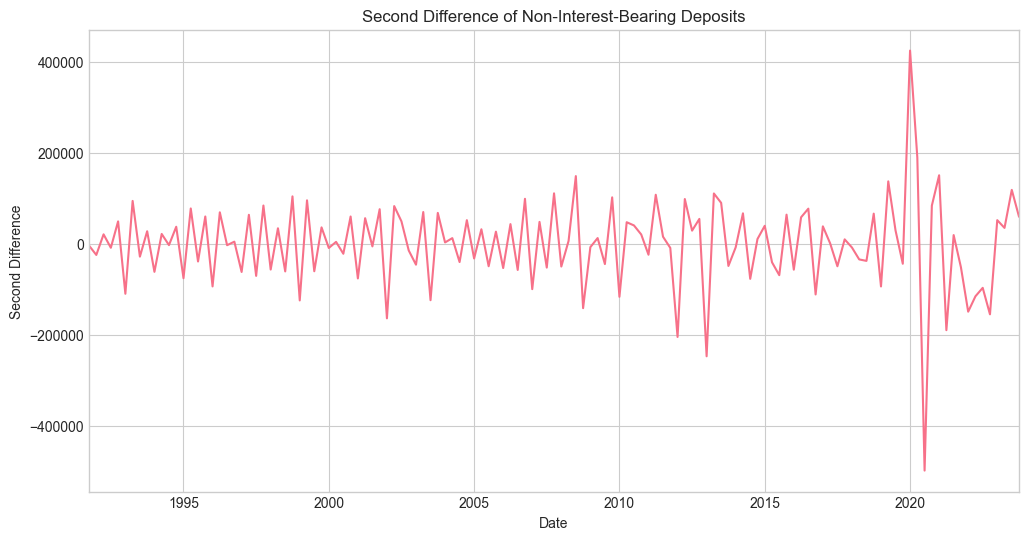

In [19]:
plt.figure(figsize=(12, 6))
y_diff2.plot(title='Second Difference of Non-Interest-Bearing Deposits')
plt.ylabel('Second Difference')
plt.xlabel('Date')
plt.grid(True)
plt.show()

In [20]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

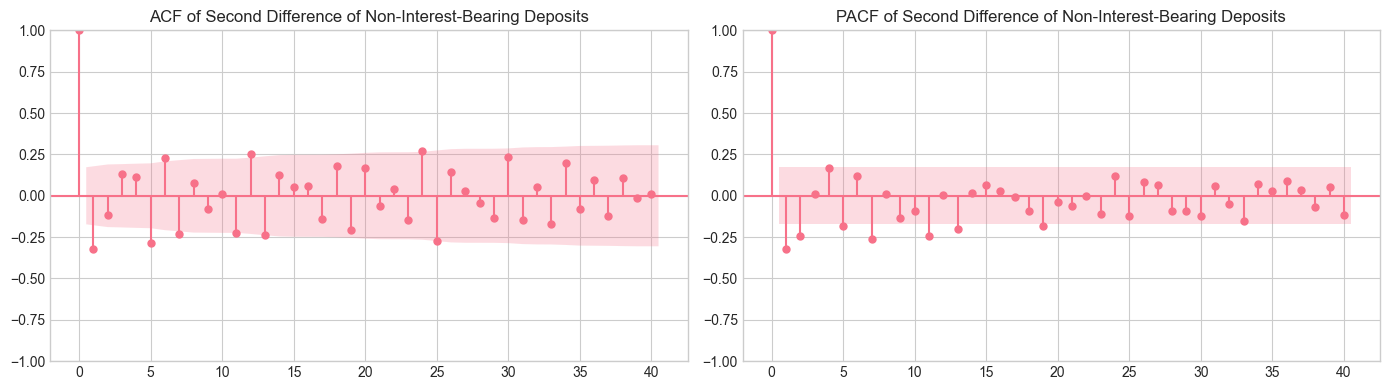

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y_diff2, lags=40, ax=axes[0])
axes[0].set_title('ACF of Second Difference of Non-Interest-Bearing Deposits')
plot_pacf(y_diff2, lags=40, ax=axes[1], method='ywm')
axes[1].set_title('PACF of Second Difference of Non-Interest-Bearing Deposits')
plt.tight_layout()
plt.savefig('graphs/non-IB/non-IB_acf_pacf.png')
plt.show()

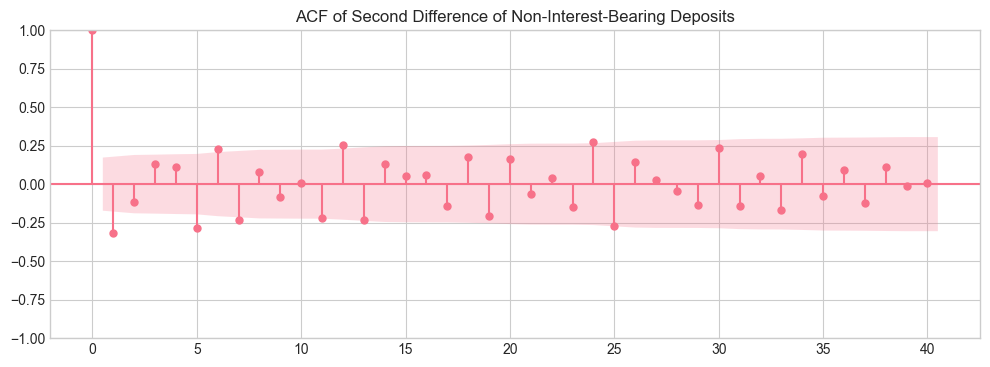

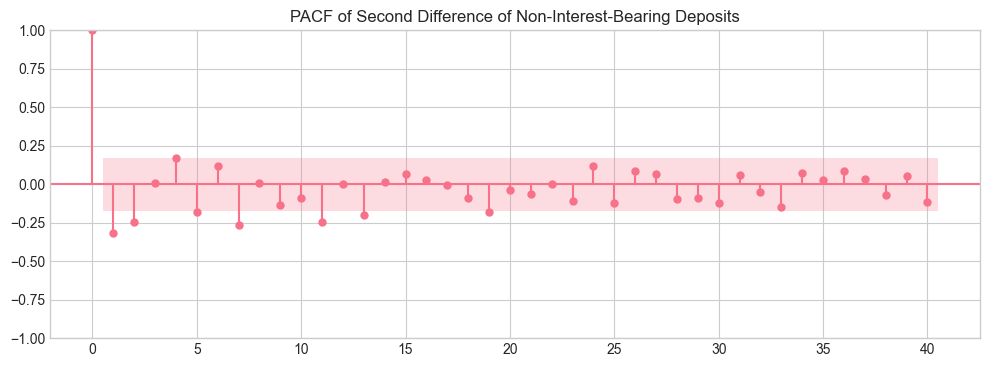

In [21]:

plt.figure(figsize=(12, 4))
plot_acf(y_diff2, lags=40, ax=plt.gca())
plt.title('ACF of Second Difference of Non-Interest-Bearing Deposits')
plt.show()

plt.figure(figsize=(12, 4))
plot_pacf(y_diff2, lags=40, ax=plt.gca(), method='ywm')
plt.title('PACF of Second Difference of Non-Interest-Bearing Deposits')
plt.show()

In [22]:
from statsmodels.tsa.stattools import kpss

In [23]:
# KPSS test with proper interpretation
kpss_stat, p_value, lags, critical_values = kpss(y_diff2.dropna(), regression='c')

print(f"KPSS Statistic: {kpss_stat:.4f}")
print(f"P-value: {p_value:.4f} (lower bound)")
print(f"Lags used: {lags}")
print(f"Critical Values: {critical_values}")

# Better interpretation accounting for the warning
if kpss_stat < critical_values['10%']:
    print(f"KPSS: Strong evidence of stationarity (stat {kpss_stat:.4f} < 10% critical {critical_values['10%']:.3f})")
    print("Note: Actual p-value > 0.10, indicating very strong stationarity")
elif p_value > 0.05:
    print("KPSS: Series is stationary")
else:
    print("KPSS: Series is non-stationary")


KPSS Statistic: 0.1264
P-value: 0.1000 (lower bound)
Lags used: 24
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
KPSS: Strong evidence of stationarity (stat 0.1264 < 10% critical 0.347)
Note: Actual p-value > 0.10, indicating very strong stationarity


/var/folders/p2/s867_82x1zb758ysgxvlj2yw0000gn/T/ipykernel_42329/148314079.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, p_value, lags, critical_values = kpss(y_diff2.dropna(), regression='c')


In [24]:
from arch.unitroot import PhillipsPerron

In [25]:
# Phillips–Perron test on second differenced data
pp_test = PhillipsPerron(y_diff2.dropna(), lags=None, trend='c')
print(pp_test.summary())

# Access individual results
print(f"PP Statistic: {pp_test.stat:.4f}")
print(f"P-value: {pp_test.pvalue:.10f}")
print(f"Lags: {pp_test.lags}")
print(f"Critical Values: {pp_test.critical_values}")


     Phillips-Perron Test (Z-tau)    
Test Statistic                -20.507
P-value                         0.000
Lags                               13
-------------------------------------

Trend: Constant
Critical Values: -3.48 (1%), -2.88 (5%), -2.58 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.
PP Statistic: -20.5067
P-value: 0.0000000000
Lags: 13
Critical Values: {'1%': -3.4825006939887997, '5%': -2.884397984161377, '10%': -2.578960197753906}


In [26]:
# Exclude the last two columns from X
X_no_dummies = X.iloc[:, :-2]
X_no_dummies.head()

,Real GDP growth,Nominal GDP growth,Real disposable income growth,Unemployment rate,CPI inflation rate,3-month Treasury rate,Prime rate
Date,,,,,,,
1991-06-30,3.2,6.2,3.0,6.8,2.4,5.6,8.7
1991-09-30,2.0,5.3,1.5,6.9,3.1,5.4,8.4
1991-12-31,1.4,3.8,3.2,7.1,3.4,4.5,7.6
1992-03-31,4.9,6.4,7.9,7.4,2.7,3.9,6.5
1992-06-30,4.4,6.9,3.8,7.6,3.1,3.7,6.5


In [27]:
# Stationarity tests for all exogenous variables
results = {}

for col in X_no_dummies.columns:
    series = X_no_dummies[col].dropna()
    # 1) Find minimum d for stationarity by ADF
    d = 0
    while True:
        stat, pval, *_ = adfuller(series, regression='c')
        if pval <= 0.05 or d == 2:
            break
        series = series.diff().dropna()
        d += 1

    # 2) Final ADF
    adf_stat, adf_p, *_ = adfuller(series, regression='c')

    # 3) KPSS with manual p-value bounds
    kpss_stat, kpss_p, _, crit = kpss(series, regression='c')
    # If stat is below the smallest critical value, the true p-value > 0.10
    if kpss_stat < crit['10%']:
        kpss_p = 1.0

    results[col] = {
        'd': d,
        'ADF p-value': round(adf_p, 4),
        'ADF stat': round(adf_stat, 4),
        'ADF crit 5%': adf_result_diff[4]['5%'],
        'KPSS p-value': round(kpss_p, 4),
        'KPSS stat': round(kpss_stat, 4),
        'KPSS 5% crit': crit['5%']
    }

stationarity_df = pd.DataFrame(results).T
print(stationarity_df)


                                 d  ADF p-value  ADF stat  ADF crit 5%  \
Real GDP growth                0.0       0.0000  -13.4782    -2.886797   
Nominal GDP growth             0.0       0.0000  -12.4228    -2.886797   
Real disposable income growth  0.0       0.0000   -6.0970    -2.886797   
Unemployment rate              0.0       0.0285   -3.0744    -2.886797   
CPI inflation rate             0.0       0.0000   -7.3205    -2.886797   
3-month Treasury rate          1.0       0.0001   -4.8018    -2.886797   
Prime rate                     1.0       0.0001   -4.7182    -2.886797   

                               KPSS p-value  KPSS stat  KPSS 5% crit  
Real GDP growth                         1.0     0.2684         0.463  
Nominal GDP growth                      1.0     0.1913         0.463  
Real disposable income growth           1.0     0.1141         0.463  
Unemployment rate                       1.0     0.1597         0.463  
CPI inflation rate                      1.0     0.15

/var/folders/p2/s867_82x1zb758ysgxvlj2yw0000gn/T/ipykernel_42329/3793422907.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, _, crit = kpss(series, regression='c')
/var/folders/p2/s867_82x1zb758ysgxvlj2yw0000gn/T/ipykernel_42329/3793422907.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, _, crit = kpss(series, regression='c')
/var/folders/p2/s867_82x1zb758ysgxvlj2yw0000gn/T/ipykernel_42329/3793422907.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, _, crit = kpss(series, regression='c')
/var/folders/p2/s867_82x1zb758ysgxvlj2yw0000gn/T/ipykernel_42329/37934

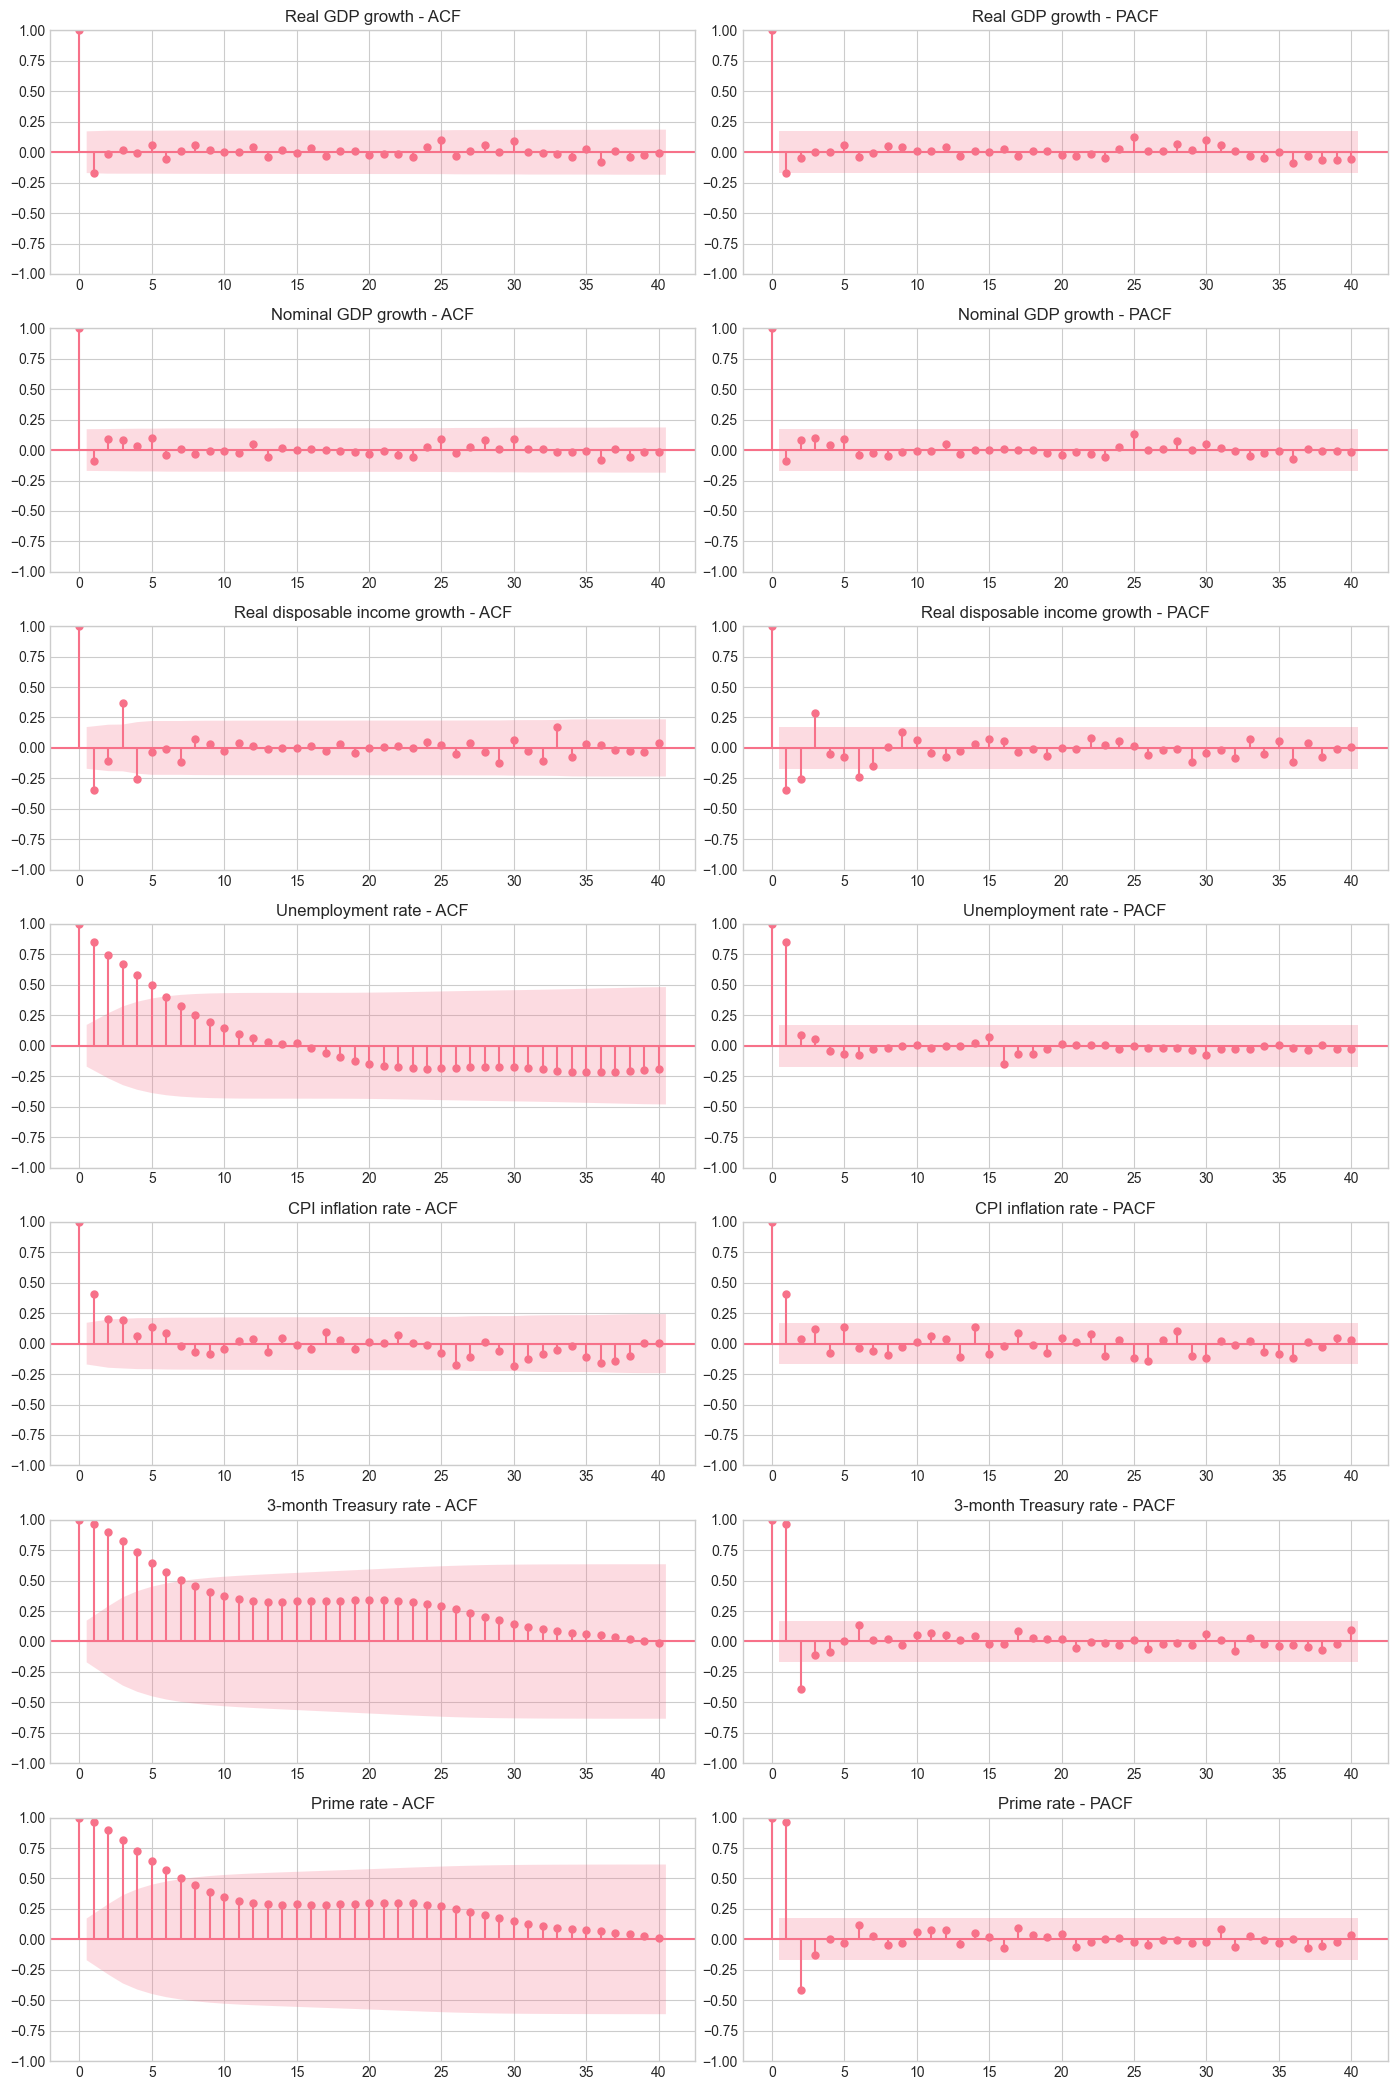

In [30]:
# ACF and PACF plots for each predictor variable
fig, axes = plt.subplots(len(X_no_dummies.columns), 2, figsize=(14, 3 * len(X_no_dummies.columns)))
for i, col in enumerate(X_no_dummies.columns):
    # ACF
    plot_acf(X_no_dummies[col].dropna(), lags=40, ax=axes[i, 0])
    axes[i, 0].set_title(f"{col} - ACF")
    # PACF
    plot_pacf(X_no_dummies[col].dropna(), lags=40, ax=axes[i, 1], method='ywm')
    axes[i, 1].set_title(f"{col} - PACF")
plt.tight_layout()
plt.savefig('graphs/non-IB/exogenous_acf_pacf.png')
plt.show()


Real GDP growth: The ACF shows a sharp spike at lag 1 then quickly dies out, while the PACF has a single significant lag 1 and the rest negligible—classic for an AR(1) process. This suggests a simple autoregressive term may capture its short-run dynamics.

Nominal GDP growth: Very similar to real GDP growth, with only lag 1 significant in both ACF and PACF, indicating minimal persistence beyond one quarter. A single AR term should suffice.

Real disposable income growth: The ACF/PACF both taper off quickly after lag 1, though there’s a small lag 3 bump in the ACF. Still, an AR(1) with possibly an MA(1) could model the mild autocorrelation.

Unemployment rate: The ACF decays slowly over many lags, pointing to longer memory, while the PACF cuts off sharply after lag 1—ideal for an AR(1) but consider extra AR terms if persistence beyond one period matters.

CPI inflation rate: A moderate ACF decline over ~5 lags and a PACF spike at lag 1 suggest an AR(1) or ARMA(1,1) to capture both direct and damped effects.

3-month Treasury rate: The ACF decays gradually and PACF shows a strong lag 1, hinting at an AR(1) structure with high persistence.

Prime rate: Nearly identical to the 3-month rate, with slow ACF decay and a single PACF spike, so an AR(1) should cover its behavior.

Non-interest-bearing deposits (2nd diff): The ACF has a pronounced negative spike at lag 1 and small positive spikes thereafter, while the PACF shows only lag 1 negative—typical of an MA(1) process induced by differencing.